# Week 6 — Fourier Spectral-Residual Detection: Localization and Confidence
One method, studied in depth. Learn the periodic weave spectrum of defect-free fabric, notch it out, and use the residual energy as a deviation map. Fixed and adaptive (per-fabric, period-driven) multi-scale pipelines are compared, then the best one is turned into clean defect masks with a calibrated confidence score, overlays, and a raw-image-to-mask demo.

**SETUP**  
Import libraries and set every tunable parameter in one place.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import random
from numpy.lib.stride_tricks import sliding_window_view
from scipy import ndimage
from scipy.signal import windows
from scipy.stats import gumbel_r, spearmanr
from sklearn.metrics import average_precision_score, roc_auc_score
from skimage.filters import threshold_otsu

SEED = 42
rng = np.random.default_rng(SEED)
random.seed(SEED)

SCALES_ALL = [32, 64, 128, 256]   # window sizes (pixels) available to the method

CFG = dict(
    # spectral peak detection and notch
    detrend=True,        # remove each window's mean and linear brightness ramp before the FFT
    peak_k=6.0,          # peak = log-spectrum prominence above k robust sigmas
    dilate_r=2,          # notch dilation (frequency bins), covers window leakage
    lowcut=1.5,          # also suppress the lowest frequencies (illumination)
    notch_depth=0.0,     # 0 = remove notched frequencies completely, 0.2 = keep 20%
    # fixed pipelines (same settings for every fabric)
    fixed_single_scales=[128],
    fixed_multi_scales=[64, 128, 256],
    fixed_sigma=4.0,     # energy smoothing (pixels)
    # adaptive rules driven by the estimated weave period P (pixels)
    c_periods=4,         # a window should hold at least c periods
    n_adapt_scales=3,    # number of consecutive scales used
    sigma_periods=1.0,   # smoothing = sigma_periods * P (clipped to 2..12)
    # calibration (on defect-free CAL patches)
    target_fpr=0.05,     # allowed fraction of defect-free patches flagged
    thr_estimator="gumbel",  # "gumbel" (fit to patch maxima) or "empirical"
    low_frac_grid=[1.0, 0.9, 0.8, 0.7, 0.6, 0.5],  # region-growing threshold as a fraction of the high threshold (1.0 = no growth)
    # mask clean-up
    r_open=1, r_close=3, min_area=16,
    # data budget (patches per fabric)
    max_ref=150, max_cal=60, max_ntest=40,
    var_threshold=5.0,   # skip flat/blank windows and patches (std below this)
    border_margin=16,    # ignore this many pixels at each patch edge (padding artefacts)
    clahe_preprocess=True,  # must match how the patch set was made (False for the no-CLAHE patch set)
)

Mounted at /content/drive


**LOAD DATASET**  
Patch folders from preprocessing, plus the raw image and mask folders (used for the raw-image demo at the end).

In [2]:
PATCHED_DIR = Path("/content/drive/MyDrive/ECE501/processed_patches")
PATCH_IMAGE_DIR = PATCHED_DIR / "images"
PATCH_MASK_DIR = PATCHED_DIR / "masks"
NODEFECT_PATCH_DIR = PATCHED_DIR / "nodefect_images"

DATASET_DIR = Path("/content/drive/MyDrive/ECE501/archive")
DEFECT_IMAGE_DIR = DATASET_DIR / "Defect_images"
MASK_DIR = DATASET_DIR / "Mask_images"
NODEFECT_IMAGE_DIR = DATASET_DIR / "NODefect_images"

defect_patch_files = sorted(PATCH_IMAGE_DIR.glob("*.png"))
nodefect_patch_files = sorted(NODEFECT_PATCH_DIR.glob("*.png"))

print("=" * 60)
print("DATASET LOADED")
print("=" * 60)
print(f"Patches from defective images : {len(defect_patch_files)}")
print(f"Defect-free patches           : {len(nodefect_patch_files)}")
print(f"Raw defect image folder found : {DEFECT_IMAGE_DIR.exists()}")

DATASET LOADED
Patches from defective images : 3222
Defect-free patches           : 4371
Raw defect image folder found : True


**HELPERS AND TABLES**  
Fabric code is the third filename token; the source image is the first three tokens. Only patches containing defect pixels are used for evaluation.

In [3]:
def get_fabric_type(stem):
    parts = stem.split("_")
    return parts[2] if len(parts) >= 3 else "unknown"

def get_source_id(stem):
    return "_".join(stem.split("_")[:3])

def load_gray(path):
    img = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    return None if img is None else img.astype(np.float32)

rows = []
for f in defect_patch_files:
    m = cv2.imread(str(PATCH_MASK_DIR / f.name), cv2.IMREAD_GRAYSCALE)
    if m is not None and np.count_nonzero(m) > 0:
        rows.append(dict(file=f, source=get_source_id(f.stem),
                         fabric=get_fabric_type(f.stem), defect_px=int(np.count_nonzero(m))))
defect_df = pd.DataFrame(rows)

nodefect_df = pd.DataFrame([dict(file=f, source=get_source_id(f.stem), fabric=get_fabric_type(f.stem))
                            for f in nodefect_patch_files])

FABRICS = sorted(set(defect_df.fabric) & set(nodefect_df.fabric))
nodefect_df = nodefect_df[nodefect_df.fabric.isin(FABRICS)].copy()

print("=" * 60)
print("PATCH TABLES")
print("=" * 60)
print(f"Defect-containing patches : {len(defect_df)}  (from {defect_df.source.nunique()} source images)")
print(f"Fabrics with both kinds   : {FABRICS}")

PATCH TABLES
Defect-containing patches : 367  (from 104 source images)
Fabrics with both kinds   : ['00', '01', '02', '03', '04', '05', '06']


**LEAK-FREE SPLITS**  
Defect patches: DEV / TEST by source image (TEST stays untouched until the final comparison). Defect-free patches: REF (learn the spectrum) / CAL (calibrate thresholds) / NTEST (measure false alarms), split by source image within each fabric.

In [4]:
# Defect patches: DEV / TEST, no source image appears in both
src = sorted(defect_df.source.unique())
perm = list(rng.permutation(src))
dev_src = set(perm[: len(perm) // 2])
defect_df["split"] = np.where(defect_df.source.isin(dev_src), "dev", "test")

# Defect-free patches: REF / CAL / NTEST per fabric, by source image
role = {}
for fab in FABRICS:
    ids = sorted(nodefect_df[nodefect_df.fabric == fab].source.unique())
    perm = list(rng.permutation(ids))
    n = len(perm)
    n_ref = max(1, int(round(0.5 * n)))
    n_cal = max(1, int(round(0.25 * n)))
    for s in perm[:n_ref]:
        role[s] = "ref"
    for s in perm[n_ref:n_ref + n_cal]:
        role[s] = "cal"
    for s in perm[n_ref + n_cal:]:
        role[s] = "ntest"
nodefect_df["role"] = nodefect_df.source.map(role)

print("=" * 60)
print("SPLIT SUMMARY")
print("=" * 60)
print("Defect patches by split (DEV is used for all development work):")
print(defect_df.groupby(["fabric", "split"]).size().unstack(fill_value=0).to_string())
print("\nDefect-free source images by role:")
print(nodefect_df.drop_duplicates("source").groupby(["fabric", "role"]).size().unstack(fill_value=0).to_string())

SPLIT SUMMARY
Defect patches by split (DEV is used for all development work):
split   dev  test
fabric           
00       11     6
01       12    41
02       41    40
03       91    85
04       14    10
05        0     2
06        8     6

Defect-free source images by role:
role    cal  ntest  ref
fabric                 
00        5      5   10
01        5      6   10
02        5      5   10
03        5      5   10
04        5      5   10
05        5      5   10
06        5      5   10


**SPECTRAL TOOLKIT**  
Windowed FFT (each window loses its mean and linear brightness ramp first), peak detection in the log-spectrum, and the notch mask (peaks, a small dilation, and the lowest frequencies).

In [5]:
HANN = {W: np.outer(windows.hann(W, sym=False), windows.hann(W, sym=False)).astype(np.float32)
        for W in SCALES_ALL}

def tile_windows(img, W):
    """Non-overlapping W x W windows (used to learn the reference spectrum)."""
    v = sliding_window_view(img, (W, W))[::W, ::W]
    return v.reshape(-1, W, W)

def padded_windows(img, W):
    """Overlapping windows (50%) on a reflect-padded image (used at test time)."""
    pad, stride = W // 2, W // 2
    p = np.pad(img, pad, mode="reflect")
    v = sliding_window_view(p, (W, W))[::stride, ::stride]
    ny, nx = v.shape[:2]
    return v.reshape(-1, W, W), ny, nx, p.shape, pad, stride

_PLANE = {}

def detrend_windows(wins, W):
    """Subtract each window's best-fit plane (mean plus linear brightness ramp)."""
    if W not in _PLANE:
        y, x = np.mgrid[0:W, 0:W]
        A = np.stack([np.ones(W * W), (x.ravel() - (W - 1) / 2) / W, (y.ravel() - (W - 1) / 2) / W], axis=1)
        _PLANE[W] = (A, np.linalg.pinv(A))
    A, P = _PLANE[W]
    flat = wins.reshape(len(wins), -1).astype(np.float64)
    return (flat - (flat @ P.T) @ A.T).reshape(len(wins), W, W).astype(np.float32)

def windowed_fft(wins, W):
    if CFG["detrend"]:
        wins = detrend_windows(wins, W)
    else:
        wins = wins - wins.mean(axis=(1, 2), keepdims=True)
    return np.fft.fft2(wins * HANN[W])

def freq_radius(W):
    k = np.fft.fftfreq(W) * W
    return np.hypot(k[:, None], k[None, :])

def peak_zscore(mag, W):
    """Prominence of each frequency bin above its smooth neighbourhood, in robust sigmas."""
    L = np.log1p(mag)
    size = max(5, (W // 16) | 1)
    bg = ndimage.median_filter(L, size=size, mode="wrap")
    d = L - bg
    mad = np.median(np.abs(d - np.median(d))) * 1.4826 + 1e-8
    return d / mad

def make_notch(mag, W, cfg):
    notch = (peak_zscore(mag, W) > cfg["peak_k"]) | (freq_radius(W) <= cfg["lowcut"])
    r = cfg["dilate_r"]
    if r > 0:
        yy, xx = np.ogrid[-r:r + 1, -r:r + 1]
        foot = (yy ** 2 + xx ** 2) <= r ** 2
        notch = ndimage.maximum_filter(notch.astype(np.uint8), footprint=foot, mode="wrap") > 0
    return notch

def top_periods(mag, W, n=3, min_rad=3, excl=3):
    """Strongest spectral peaks as (period in pixels, prominence z)."""
    z = peak_zscore(mag, W).copy()
    z[freq_radius(W) <= min_rad] = -np.inf
    k = np.fft.fftfreq(W) * W
    out = []
    for _ in range(n):
        iy, ix = np.unravel_index(np.argmax(z), z.shape)
        out.append((float(W / np.hypot(k[iy], k[ix])), float(z[iy, ix])))
        for cy, cx in ((iy, ix), ((-iy) % W, (-ix) % W)):
            ys = np.arange(cy - excl, cy + excl + 1) % W
            xs = np.arange(cx - excl, cx + excl + 1) % W
            z[np.ix_(ys, xs)] = -np.inf
    return out

**REFERENCE SPECTRA (FEASIBILITY CHECK)**  
Mean windowed magnitude spectrum of the REF defect-free patches, per fabric and window size. Sharp peaks mean the weave is periodic enough for the method.

In [6]:
def sample_files(files, cap, rng):
    files = list(files)
    if len(files) > cap:
        idx = rng.choice(len(files), size=cap, replace=False)
        files = [files[i] for i in sorted(idx)]
    return files

def build_reference_spectra(files, cfg):
    sums = {W: np.zeros((W, W)) for W in SCALES_ALL}
    cnt = {W: 0 for W in SCALES_ALL}
    for f in files:
        img = load_gray(f)
        if img is None:
            continue
        for W in SCALES_ALL:
            tiles = tile_windows(img, W)
            keep = tiles.std(axis=(1, 2)) >= cfg["var_threshold"]
            if keep.any():
                sums[W] += np.abs(windowed_fft(tiles[keep], W)).sum(axis=0)
                cnt[W] += int(keep.sum())
    return sums, cnt

ref_sums, ref_cnt, mags = {}, {}, {}
for fab in FABRICS:
    files = nodefect_df[(nodefect_df.fabric == fab) & (nodefect_df.role == "ref")].file.tolist()
    files = sample_files(files, CFG["max_ref"], rng)
    ref_sums[fab], ref_cnt[fab] = build_reference_spectra(files, CFG)
    mags[fab] = {W: ref_sums[fab][W] / max(ref_cnt[fab][W], 1) for W in SCALES_ALL}

# Pooled reference for the fixed pipelines: count-weighted mean over all fabrics
pooled_mags = {W: sum(ref_sums[f][W] for f in FABRICS) / max(sum(ref_cnt[f][W] for f in FABRICS), 1)
               for W in SCALES_ALL}

print("=" * 60)
print("REFERENCE SPECTRA BUILT")
print("=" * 60)
for fab in FABRICS:
    print(f"Fabric {fab} : {ref_cnt[fab][256]} patches (256x256), {ref_cnt[fab][64]} windows at 64x64")

REFERENCE SPECTRA BUILT
Fabric 00 : 117 patches (256x256), 1804 windows at 64x64
Fabric 01 : 142 patches (256x256), 2248 windows at 64x64
Fabric 02 : 150 patches (256x256), 2352 windows at 64x64
Fabric 03 : 119 patches (256x256), 1848 windows at 64x64
Fabric 04 : 150 patches (256x256), 2400 windows at 64x64
Fabric 05 : 150 patches (256x256), 2324 windows at 64x64
Fabric 06 : 150 patches (256x256), 2400 windows at 64x64


**PERIODICITY TABLE AND SPECTRA**  
Per fabric: dominant weave periods, how sharp the strongest peak is, and how much spectral energy the notch removes.

PERIODICITY OF DEFECT-FREE FABRIC (256x256 spectra)
fabric top_periods_px  peak_strength_z  notch_energy_pct
    00  5.7, 4.7, 5.6             67.1              84.3
    01  5.1, 3.4, 5.1             62.5              75.1
    02  4.2, 4.4, 2.1             71.0              83.5
    03  5.9, 5.7, 4.7             71.9              95.0
    04  5.4, 5.8, 6.1             65.3              63.2
    05  4.2, 4.2, 2.1             55.1              58.8
    06 5.6, 5.9, 15.1             68.2              72.7


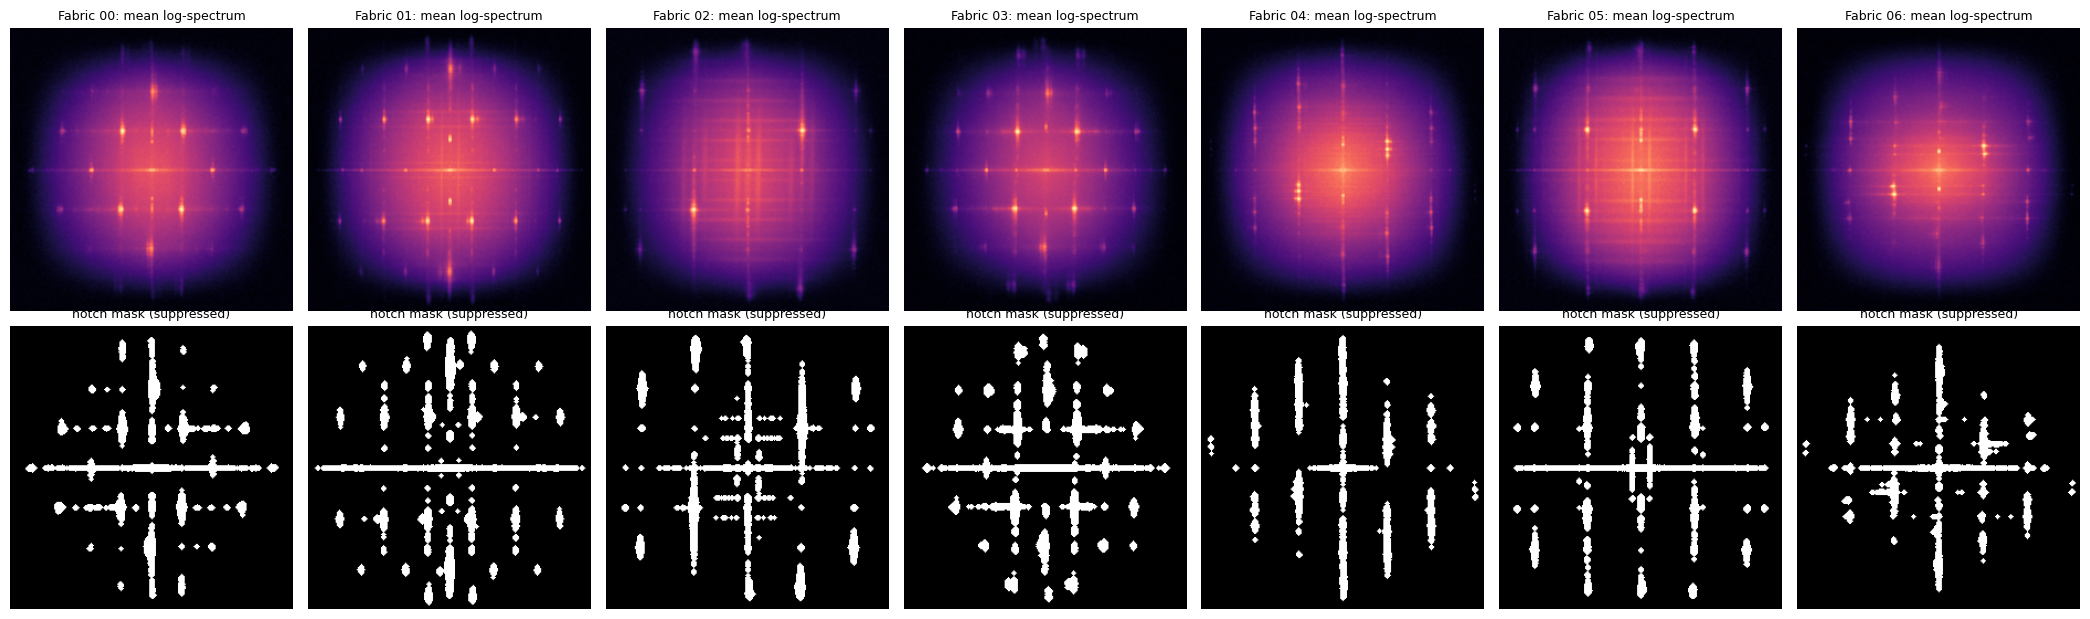

In [7]:
cfg_nolow = {**CFG, "lowcut": 0}
feas = []
for fab in FABRICS:
    mag = mags[fab][256].copy()
    mag[0, 0] = 0
    peaks = top_periods(mags[fab][256], 256, n=3)
    notch_peaks = make_notch(mags[fab][256], 256, cfg_nolow)
    energy = float((mag ** 2)[notch_peaks].sum() / (mag ** 2).sum())
    feas.append(dict(fabric=fab,
                     top_periods_px=", ".join(f"{p:.1f}" for p, _ in peaks),
                     peak_strength_z=round(peaks[0][1], 1),
                     notch_energy_pct=round(100 * energy, 1)))
feas_df = pd.DataFrame(feas)

print("=" * 60)
print("PERIODICITY OF DEFECT-FREE FABRIC (256x256 spectra)")
print("=" * 60)
print(feas_df.to_string(index=False))

fig, axes = plt.subplots(2, len(FABRICS), figsize=(3 * len(FABRICS), 6.2))
axes = np.atleast_2d(axes).reshape(2, -1)
for j, fab in enumerate(FABRICS):
    axes[0, j].imshow(np.fft.fftshift(np.log1p(mags[fab][256])), cmap="magma")
    axes[0, j].set_title(f"Fabric {fab}: mean log-spectrum", fontsize=9)
    axes[1, j].imshow(np.fft.fftshift(make_notch(mags[fab][256], 256, CFG)), cmap="gray")
    axes[1, j].set_title("notch mask (suppressed)", fontsize=9)
    axes[0, j].axis("off"); axes[1, j].axis("off")
plt.tight_layout()
plt.show()

**ADAPTIVE PARAMETER RULES**  
The estimated weave period P (strongest spectral peak) sets each fabric's window sizes and smoothing: windows must hold at least c periods, and smoothing is about one period.

In [8]:
def adaptive_params(P, cfg):
    need = cfg["c_periods"] * P
    cand = [W for W in SCALES_ALL if W >= need] or [SCALES_ALL[-1]]
    start = SCALES_ALL.index(cand[0])
    scales = SCALES_ALL[start:start + cfg["n_adapt_scales"]]
    sigma = float(np.clip(P * cfg["sigma_periods"], 2, 12))
    return scales, sigma

adapt_params = {}
for fab in FABRICS:
    P = top_periods(mags[fab][256], 256, n=1)[0][0]
    scales, sigma = adaptive_params(P, CFG)
    adapt_params[fab] = dict(P=P, scales=scales, sigma=sigma)

print("=" * 60)
print("ADAPTIVE PARAMETERS PER FABRIC")
print("=" * 60)
for fab in FABRICS:
    a = adapt_params[fab]
    print(f"Fabric {fab} : period {a['P']:.1f} px -> scales {a['scales']}, smoothing sigma {a['sigma']:.1f}")
print(f"\nFixed multi-scale uses {CFG['fixed_multi_scales']} and sigma {CFG['fixed_sigma']} for every fabric.")

ADAPTIVE PARAMETERS PER FABRIC
Fabric 00 : period 5.7 px -> scales [32, 64, 128], smoothing sigma 5.7
Fabric 01 : period 5.1 px -> scales [32, 64, 128], smoothing sigma 5.1
Fabric 02 : period 4.2 px -> scales [32, 64, 128], smoothing sigma 4.2
Fabric 03 : period 5.9 px -> scales [32, 64, 128], smoothing sigma 5.9
Fabric 04 : period 5.4 px -> scales [32, 64, 128], smoothing sigma 5.4
Fabric 05 : period 4.2 px -> scales [32, 64, 128], smoothing sigma 4.2
Fabric 06 : period 5.6 px -> scales [32, 64, 128], smoothing sigma 5.6

Fixed multi-scale uses [64, 128, 256] and sigma 4.0 for every fabric.


**RESIDUAL-ENERGY ENGINE**  
For each overlapping window: FFT, remove the notched frequencies, inverse FFT. Overlap-added squared residuals give a local energy map (log scale), lightly smoothed.

In [9]:
_H2_CACHE = {}

def hann_overlap(W, pshape):
    key = (W, pshape)
    if key not in _H2_CACHE:
        stride = W // 2
        acc = np.zeros(pshape, dtype=np.float32)
        h2 = HANN[W] ** 2
        for y in range(0, pshape[0] - W + 1, stride):
            for x in range(0, pshape[1] - W + 1, stride):
                acc[y:y + W, x:x + W] += h2
        _H2_CACHE[key] = np.maximum(acc, 1e-3)
    return _H2_CACHE[key]

def residual_log_energy(img, W, notch, sigma, depth=0.0):
    wins, ny, nx, pshape, pad, stride = padded_windows(img, W)
    F = windowed_fft(wins, W)
    F = np.where(notch, F * depth, F)
    r = np.fft.ifft2(F).real.astype(np.float32)
    acc = np.zeros(pshape, dtype=np.float32)
    k = 0
    for iy in range(ny):
        for ix in range(nx):
            y, x = iy * stride, ix * stride
            acc[y:y + W, x:x + W] += r[k] ** 2
            k += 1
    E = (acc / hann_overlap(W, pshape))[pad:-pad, pad:-pad]
    if sigma > 0:
        E = ndimage.gaussian_filter(E, sigma, mode="reflect")
    return np.log(E + 1e-3)

**MODEL FITTING, THRESHOLDS AND CONFIDENCE**  
Scores are computed on the patch interior only (padding a periodic texture creates edge artefacts, and patches overlap by 50%). A model holds the notch per scale, a robust normalisation per scale, and a detection threshold calibrated on CAL defect-free patches (flags at most the target share of normal patches). Confidence is the probability that a normal patch would score below the observed peak.

In [10]:
def interior(a):
    m = CFG["border_margin"]
    return a[m:-m, m:-m] if m > 0 else a

def make_model(name, scales, sigma, mag_dict, cfg):
    return dict(name=name, scales=list(scales), sigma=float(sigma), depth=float(cfg["notch_depth"]),
                notch={W: make_notch(mag_dict[W], W, cfg) for W in scales},
                stats={}, thr=None, gumbel=None, cal_max=None)

def fit_model(model, cal_imgs, cfg):
    maps = {W: np.stack([interior(residual_log_energy(im, W, model["notch"][W], model["sigma"], model["depth"]))
                         for im in cal_imgs]) for W in model["scales"]}
    z = []
    for W in model["scales"]:
        med = np.median(maps[W])
        mad = np.median(np.abs(maps[W] - med)) * 1.4826 + 1e-6
        model["stats"][W] = (float(med), float(mad))
        z.append((maps[W] - med) / mad)
    zmax = np.max(z, axis=0)
    patch_max = zmax.reshape(len(cal_imgs), -1).max(axis=1)
    model["cal_max"] = np.sort(patch_max)
    thr = None
    if cfg["thr_estimator"] == "gumbel":
        try:
            loc, scale = gumbel_r.fit(patch_max)
            model["gumbel"] = (float(loc), float(scale))
            thr = float(gumbel_r.ppf(1 - cfg["target_fpr"], loc, scale))
        except Exception:
            model["gumbel"] = None
    if thr is None:
        thr = float(np.quantile(patch_max, 1 - cfg["target_fpr"]))
    model["thr"] = thr
    return model

def confidence(model, peak):
    """Probability that a defect-free patch would have a lower peak score than this one."""
    if model["gumbel"] is not None:
        return float(gumbel_r.cdf(peak, *model["gumbel"]))
    return float(np.mean(model["cal_max"] < peak))

def deviation_map(img, model):
    zs = []
    for W in model["scales"]:
        e = residual_log_energy(img, W, model["notch"][W], model["sigma"], model["depth"])
        med, mad = model["stats"][W]
        zs.append(interior((e - med) / mad))
    return np.max(zs, axis=0)

**CACHE IMAGES**  
Load the capped CAL, NTEST and DEV patches once (blank patches skipped for defect-free sets). DEV patches whose defect lies only in the ignored border margin are dropped.

In [11]:
def load_valid(files, cap, rng, cfg):
    files = sample_files(files, cap * 2, rng)
    out = []
    for f in files:
        img = load_gray(f)
        if img is not None and img.std() >= cfg["var_threshold"]:
            out.append(img)
        if len(out) >= cap:
            break
    return out

cal_imgs, ntest_imgs = {}, {}
for fab in FABRICS:
    sub = nodefect_df[nodefect_df.fabric == fab]
    cal_imgs[fab] = load_valid(sub[sub.role == "cal"].file.tolist(), CFG["max_cal"], rng, CFG)
    ntest_imgs[fab] = load_valid(sub[sub.role == "ntest"].file.tolist(), CFG["max_ntest"], rng, CFG)

dev_items = []   # dicts: fabric, name, source, img (full patch), gt (interior, bool)
skipped_margin = 0
for _, r in defect_df[defect_df.split == "dev"].iterrows():
    img = load_gray(r.file)
    gt = cv2.imread(str(PATCH_MASK_DIR / r.file.name), cv2.IMREAD_GRAYSCALE)
    if img is None or gt is None:
        continue
    gt_i = interior(gt > 0)
    if not gt_i.any():
        skipped_margin += 1
        continue
    dev_items.append(dict(fabric=r.fabric, name=r.file.name, source=r.source, img=img, gt=gt_i))

print("=" * 60)
print("CACHED IMAGES")
print("=" * 60)
print(f"CAL patches        : {sum(len(v) for v in cal_imgs.values())}")
print(f"NTEST patches      : {sum(len(v) for v in ntest_imgs.values())}")
print(f"DEV defect patches : {len(dev_items)}  (skipped, defect only in margin: {skipped_margin})")

CACHED IMAGES
CAL patches        : 420
NTEST patches      : 280
DEV defect patches : 152  (skipped, defect only in margin: 25)


**BUILD THE THREE PIPELINES**  
Fixed single-scale and fixed multi-scale use one pooled reference, one smoothing and one threshold for all fabrics. Adaptive multi-scale builds a separate model per fabric from its own weave period.

In [12]:
def build_adaptive_models(cfg):
    out = {}
    for fab in FABRICS:
        a = adapt_params[fab]
        out[fab] = fit_model(make_model(f"adaptive_{fab}", a["scales"], a["sigma"], mags[fab], cfg), cal_imgs[fab], cfg)
    return out

pooled_cal = [im for fab in FABRICS for im in cal_imgs[fab]]

models = {}
models["Fixed single-scale"] = fit_model(
    make_model("fixed_single", CFG["fixed_single_scales"], CFG["fixed_sigma"], pooled_mags, CFG), pooled_cal, CFG)
models["Fixed multi-scale"] = fit_model(
    make_model("fixed_multi", CFG["fixed_multi_scales"], CFG["fixed_sigma"], pooled_mags, CFG), pooled_cal, CFG)
adaptive_models = build_adaptive_models(CFG)

PIPELINES = ["Fixed single-scale", "Fixed multi-scale", "Adaptive multi-scale"]

def get_model(pipeline, fabric):
    return adaptive_models[fabric] if pipeline == "Adaptive multi-scale" else models[pipeline]

print("=" * 60)
print("MODELS FITTED")
print("=" * 60)
for name in PIPELINES[:2]:
    m = models[name]
    print(f"{name:22s}: threshold {m['thr']:.2f}")
for fab in FABRICS:
    m = adaptive_models[fab]
    print(f"Adaptive, fabric {fab}  : scales {m['scales']}, threshold {m['thr']:.2f}")

MODELS FITTED
Fixed single-scale    : threshold 4.38
Fixed multi-scale     : threshold 4.68
Adaptive, fabric 00  : scales [32, 64, 128], threshold 4.54
Adaptive, fabric 01  : scales [32, 64, 128], threshold 4.82
Adaptive, fabric 02  : scales [32, 64, 128], threshold 5.55
Adaptive, fabric 03  : scales [32, 64, 128], threshold 5.02
Adaptive, fabric 04  : scales [32, 64, 128], threshold 4.70
Adaptive, fabric 05  : scales [32, 64, 128], threshold 5.20
Adaptive, fabric 06  : scales [32, 64, 128], threshold 5.56


**DEVIATION-MAP QUALITY**  
Threshold-free comparison of the three pipelines on DEV: average precision (AP) and AUROC on the deviation map, with scores shifted so each model's threshold is zero. AP chance level equals the defect pixel fraction. Macro AP averages over fabrics and is not affected by calibration differences between fabrics.

In [13]:
dev_D = {p: [deviation_map(it["img"], get_model(p, it["fabric"])) for it in dev_items] for p in PIPELINES}

def map_quality(pipeline):
    subs = []
    for it, D in zip(dev_items, dev_D[pipeline]):
        thr = get_model(pipeline, it["fabric"])["thr"]
        subs.append((it["fabric"], (D - thr)[::2, ::2].ravel(), it["gt"][::2, ::2].ravel()))
    d = np.concatenate([s[1] for s in subs]); g = np.concatenate([s[2] for s in subs])
    per_fab = {}
    for fab in FABRICS:
        sel = [s for s in subs if s[0] == fab]
        if sel:
            gf = np.concatenate([s[2] for s in sel])
            per_fab[fab] = average_precision_score(gf, np.concatenate([s[1] for s in sel])) if gf.any() else np.nan
    return dict(AP=average_precision_score(g, d), MacroAP=float(np.nanmean(list(per_fab.values()))),
                AUROC=roc_auc_score(g, d)), per_fab, float(g.mean())

quality, fab_ap = {}, {}
for p in PIPELINES:
    quality[p], fab_ap[p], prevalence = map_quality(p)

print("=" * 60)
print("DEVIATION-MAP QUALITY (DEV split)")
print("=" * 60)
print(pd.DataFrame(quality).T.round(3).to_string())
print(f"\nDEV patches: {len(dev_items)} | defect pixel fraction (AP chance level): {prevalence:.4f}")
print("\nAverage precision by fabric:")
fab_table = pd.DataFrame(fab_ap).round(3)
fab_table.insert(0, "patches", [sum(1 for it in dev_items if it["fabric"] == f) for f in fab_table.index])
print(fab_table.to_string())

BEST = max(PIPELINES, key=lambda p: quality[p]["MacroAP"])
print(f"\nPipeline carried forward (highest Macro AP): {BEST}")

DEVIATION-MAP QUALITY (DEV split)
                         AP  MacroAP  AUROC
Fixed single-scale    0.035    0.116  0.551
Fixed multi-scale     0.036    0.209  0.552
Adaptive multi-scale  0.080    0.084  0.797

DEV patches: 152 | defect pixel fraction (AP chance level): 0.0328

Average precision by fabric:
    patches  Fixed single-scale  Fixed multi-scale  Adaptive multi-scale
00       11               0.086              0.024                 0.010
01        8               0.296              0.446                 0.034
02       33               0.006              0.007                 0.017
03       85               0.142              0.134                 0.251
04       10               0.157              0.600                 0.147
06        5               0.007              0.040                 0.047

Pipeline carried forward (highest Macro AP): Fixed multi-scale


**LOCALIZATION AND POST-PROCESSING**  
From a deviation map to a clean mask: seeds are pixels above the calibrated threshold; regions can grow into connected pixels above a fraction of that threshold (hysteresis, fraction tuned on DEV); then morphological opening and closing, hole filling, and removal of small blobs. Each blob gets a confidence from its peak score.

In [14]:
def disk(r):
    yy, xx = np.ogrid[-r:r + 1, -r:r + 1]
    return (yy ** 2 + xx ** 2) <= r * r

def morph(mask, r, op):
    if r <= 0:
        return mask
    pad = r + 1
    p = np.pad(mask, pad, mode="edge")
    fn = ndimage.binary_opening if op == "open" else ndimage.binary_closing
    return fn(p, structure=disk(r))[pad:-pad, pad:-pad]

def remove_small(mask, min_area):
    if min_area <= 0 or not mask.any():
        return mask
    lab, _ = ndimage.label(mask)
    keep = np.bincount(lab.ravel()) >= min_area
    keep[0] = False
    return keep[lab]

def postprocess(mask, cfg):
    m = morph(mask, cfg["r_open"], "open")
    m = morph(m, cfg["r_close"], "close")
    m = ndimage.binary_fill_holes(m)
    return remove_small(m, cfg["min_area"])

LOW_FRAC = 1.0   # set by tuning on DEV below (1.0 = no region growing)

def hysteresis(D, model, frac=None):
    """Seeds above the detection threshold grow into connected pixels above frac * threshold."""
    frac = LOW_FRAC if frac is None else frac
    seeds = D > model["thr"]
    if frac >= 1.0 or not seeds.any():
        return seeds
    lab, _ = ndimage.label(D > frac * model["thr"])
    ids = np.unique(lab[seeds])
    return np.isin(lab, ids[ids > 0])

def mask_otsu(D, model):
    n = (D - D.min()) / (D.max() - D.min() + 1e-9)
    try:
        return n > threshold_otsu(n)
    except ValueError:
        return np.zeros(D.shape, dtype=bool)

def mask_single(D, model):
    return D > model["thr"]

def mask_clean(D, model):
    return postprocess(D > model["thr"], CFG)

def mask_full(D, model):
    return postprocess(hysteresis(D, model), CFG)

def describe_blobs(mask, D, model):
    lab, n = ndimage.label(mask)
    out = []
    for i in range(1, n + 1):
        reg = lab == i
        ys, xs = np.nonzero(reg)
        peak = float(D[reg].max())
        out.append(dict(area=int(reg.sum()), peak=peak, mean=float(D[reg].mean()),
                        conf=confidence(model, peak), cy=float(ys.mean()), cx=float(xs.mean())))
    return out

def predict_from_D(D, model):
    mask = mask_full(D, model)
    blobs = describe_blobs(mask, D, model)
    conf = max((b["conf"] for b in blobs), default=confidence(model, float(D.max())))
    return dict(mask=mask, blobs=blobs, conf=conf, flag=len(blobs) > 0)

**MASK STRATEGY COMPARISON AND EXTENT TUNING**  
Same deviation maps, turned into masks four ways: per-image Otsu (always splits, even on normal patches), the calibrated threshold, plus clean-up, plus region growing. The growth fraction is chosen on DEV from a small grid (1.0 means no growth, so growth is only used if it helps). Over-segmentation ratio = predicted pixels / true defect pixels (1.0 is ideal). FPR = share of held-out defect-free patches with any predicted pixel.

In [15]:
ntest_items = []   # dicts: fabric, img (full patch)
for fab in FABRICS:
    for im in ntest_imgs[fab]:
        ntest_items.append(dict(fabric=fab, img=im))
ntest_D = [deviation_map(it["img"], get_model(BEST, it["fabric"])) for it in ntest_items]
best_dev_D = dev_D[BEST]

def patch_metrics(pred, gt):
    tp = int((pred & gt).sum()); fp = int((pred & ~gt).sum()); fn = int((~pred & gt).sum())
    iou = tp / (tp + fp + fn + 1e-9)
    p = tp / (tp + fp + 1e-9); r = tp / (tp + fn + 1e-9)
    return tp, fp, fn, iou, p, r, 2 * p * r / (p + r + 1e-9)

def eval_strategy(fn):
    tps = fps = fns = 0; ious = []; flagged = 0; pred_px = gt_px = 0
    for it, D in zip(dev_items, best_dev_D):
        pred = fn(D, get_model(BEST, it["fabric"]))
        tp, fp, fn_, iou, *_ = patch_metrics(pred, it["gt"])
        tps += tp; fps += fp; fns += fn_; ious.append(iou)
        flagged += int(pred.any()); pred_px += int(pred.sum()); gt_px += int(it["gt"].sum())
    p = tps / (tps + fps + 1e-9); r = tps / (tps + fns + 1e-9)
    fa = [fn(D, get_model(BEST, it["fabric"])).any() for it, D in zip(ntest_items, ntest_D)]
    return {"Mean IoU": np.mean(ious), "Pooled IoU": tps / (tps + fps + fns + 1e-9),
            "Pooled P": p, "Pooled R": r, "Pooled F1": 2 * p * r / (p + r + 1e-9),
            "Over-seg ratio": pred_px / max(gt_px, 1),
            "Defect-patch detection": flagged / len(dev_items), "Normal-patch FPR": float(np.mean(fa))}

# Extent tuning: region-growing fraction chosen by pooled F1 on DEV
grow_rows = {}
for frac in CFG["low_frac_grid"]:
    grow_rows[frac] = eval_strategy(lambda D, m, f=frac: postprocess(hysteresis(D, m, f), CFG))
grow_df = pd.DataFrame(grow_rows).T
grow_df.index.name = "growth fraction"
LOW_FRAC = float(grow_df["Pooled F1"].idxmax())

print("=" * 60)
print("REGION-GROWING FRACTION (DEV, with clean-up)")
print("=" * 60)
print(grow_df[["Pooled P", "Pooled R", "Pooled F1", "Over-seg ratio", "Normal-patch FPR"]].round(3).to_string())
print(f"\nChosen growth fraction: {LOW_FRAC} ({'no growth' if LOW_FRAC >= 1.0 else 'growth helps on DEV'})")

STRATEGIES = {"Otsu per image": mask_otsu, "Calibrated threshold": mask_single,
              "+ clean-up": mask_clean, "+ region growing (tuned)": mask_full}
strategy_df = pd.DataFrame({name: eval_strategy(fn) for name, fn in STRATEGIES.items()}).T

print("\n" + "=" * 60)
print(f"MASK STRATEGIES ON DEV ({BEST})")
print("=" * 60)
print(strategy_df.round(3).to_string())

REGION-GROWING FRACTION (DEV, with clean-up)
                 Pooled P  Pooled R  Pooled F1  Over-seg ratio  Normal-patch FPR
growth fraction                                                                 
1.0                 0.017     0.031      0.022           1.839             0.014
0.9                 0.018     0.037      0.024           2.102             0.018
0.8                 0.018     0.040      0.025           2.248             0.018
0.7                 0.018     0.043      0.025           2.436             0.018
0.6                 0.015     0.046      0.023           2.993             0.018
0.5                 0.015     0.052      0.023           3.484             0.018

Chosen growth fraction: 0.7 (growth helps on DEV)

MASK STRATEGIES ON DEV (Fixed multi-scale)
                          Mean IoU  Pooled IoU  Pooled P  Pooled R  Pooled F1  Over-seg ratio  Defect-patch detection  Normal-patch FPR
Otsu per image               0.070       0.062     0.063     0.825      0.11

**FINAL PIPELINE ON DEV**  
The full mask pipeline (hysteresis + clean-up) with an image-level confidence for every patch.

In [16]:
final_dev = []
for it, D in zip(dev_items, best_dev_D):
    model = get_model(BEST, it["fabric"])
    res = predict_from_D(D, model)
    iou = patch_metrics(res["mask"], it["gt"])[3]
    final_dev.append(dict(it=it, D=D, res=res, iou=iou))

final_ntest = []
for it, D in zip(ntest_items, ntest_D):
    model = get_model(BEST, it["fabric"])
    final_ntest.append(dict(it=it, D=D, res=predict_from_D(D, model)))

dev_conf = np.array([f["res"]["conf"] for f in final_dev])
dev_iou = np.array([f["iou"] for f in final_dev])
dev_flag = np.array([f["res"]["flag"] for f in final_dev])
nt_conf = np.array([f["res"]["conf"] for f in final_ntest])
nt_flag = np.array([f["res"]["flag"] for f in final_ntest])

auroc_img = roc_auc_score(np.r_[np.ones(len(dev_conf)), np.zeros(len(nt_conf))], np.r_[dev_conf, nt_conf])

print("=" * 60)
print("FINAL PIPELINE SUMMARY (DEV + NTEST)")
print("=" * 60)
print(f"Defect patches detected      : {dev_flag.mean():.3f}  ({int(dev_flag.sum())} of {len(dev_flag)})")
print(f"Normal patches flagged (FPR) : {nt_flag.mean():.3f}  ({int(nt_flag.sum())} of {len(nt_flag)})")
print(f"Image-level AUROC (confidence): {auroc_img:.3f}")
print(f"Mean IoU on detected patches  : {dev_iou[dev_flag].mean() if dev_flag.any() else float('nan'):.3f}")

FINAL PIPELINE SUMMARY (DEV + NTEST)
Defect patches detected      : 0.257  (39 of 152)
Normal patches flagged (FPR) : 0.018  (5 of 280)
Image-level AUROC (confidence): 0.822
Mean IoU on detected patches  : 0.124


**CONFIDENCE VALIDATION**  
Is the confidence score meaningful? (1) Calibration: on held-out defect-free patches, the share with confidence above c should be about 1 - c. (2) Does confidence rank accuracy? (3) Reliability: how often a patch in each confidence bin really contains a defect.

In [17]:
print("=" * 60)
print("CALIBRATION ON HELD-OUT DEFECT-FREE PATCHES")
print("=" * 60)
peak_conf_nt = np.array([confidence(get_model(BEST, f["it"]["fabric"]), float(f["D"].max())) for f in final_ntest])
cal_rows = [dict(confidence_above=c, expected_share=round(1 - c, 3), observed_share=round(float((peak_conf_nt >= c).mean()), 3))
            for c in (0.5, 0.8, 0.9, 0.95, 0.99)]
print(pd.DataFrame(cal_rows).to_string(index=False))

print("\n" + "=" * 60)
print("DOES CONFIDENCE TRACK ACCURACY? (DEV patches)")
print("=" * 60)
rho_all, _ = spearmanr(dev_conf, dev_iou)
print(f"Spearman(confidence, IoU), all DEV patches      : {rho_all:.3f}")
if dev_flag.sum() > 3:
    rho_f, _ = spearmanr(dev_conf[dev_flag], dev_iou[dev_flag])
    print(f"Spearman(confidence, IoU), detected patches only : {rho_f:.3f}")

print("\n" + "=" * 60)
print("RELIABILITY BY CONFIDENCE BIN (DEV defect + NTEST defect-free)")
print("=" * 60)
edges = [0, 0.5, 0.8, 0.9, 0.95, 0.99, 1.0001]
all_conf = np.r_[dev_conf, nt_conf]
is_def = np.r_[np.ones(len(dev_conf), bool), np.zeros(len(nt_conf), bool)]
all_iou = np.r_[dev_iou, np.full(len(nt_conf), np.nan)]
rel = []
for lo, hi in zip(edges[:-1], edges[1:]):
    sel = (all_conf >= lo) & (all_conf < hi)
    n = int(sel.sum())
    rel.append(dict(confidence_bin=f"{lo:.2f}-{min(hi, 1.0):.2f}", patches=n,
                    share_with_defect=round(float(is_def[sel].mean()), 3) if n else np.nan,
                    mean_IoU_defect_patches=round(float(np.nanmean(all_iou[sel])), 3) if sel.any() and np.isfinite(all_iou[sel]).any() else np.nan))
print(pd.DataFrame(rel).to_string(index=False))
print("\nNote: share_with_defect depends on the mix of defect and normal patches used here.")

CALIBRATION ON HELD-OUT DEFECT-FREE PATCHES
 confidence_above  expected_share  observed_share
             0.50            0.50           0.446
             0.80            0.20           0.061
             0.90            0.10           0.018
             0.95            0.05           0.018
             0.99            0.01           0.004

DOES CONFIDENCE TRACK ACCURACY? (DEV patches)
Spearman(confidence, IoU), all DEV patches      : 0.701
Spearman(confidence, IoU), detected patches only : -0.057

RELIABILITY BY CONFIDENCE BIN (DEV defect + NTEST defect-free)
confidence_bin  patches  share_with_defect  mean_IoU_defect_patches
     0.00-0.50      183              0.153                    0.000
     0.50-0.80      131              0.176                    0.000
     0.80-0.90       53              0.774                    0.000
     0.90-0.95       21              1.000                    0.000
     0.95-0.99       24              0.833                    0.151
     0.99-1.00       20

**OVERLAYS: DETECTIONS**  
Six DEV patches from different source images (three largest defects, three random). Red = predicted region, green = ground truth. The deviation map uses the same colour scale in every panel.

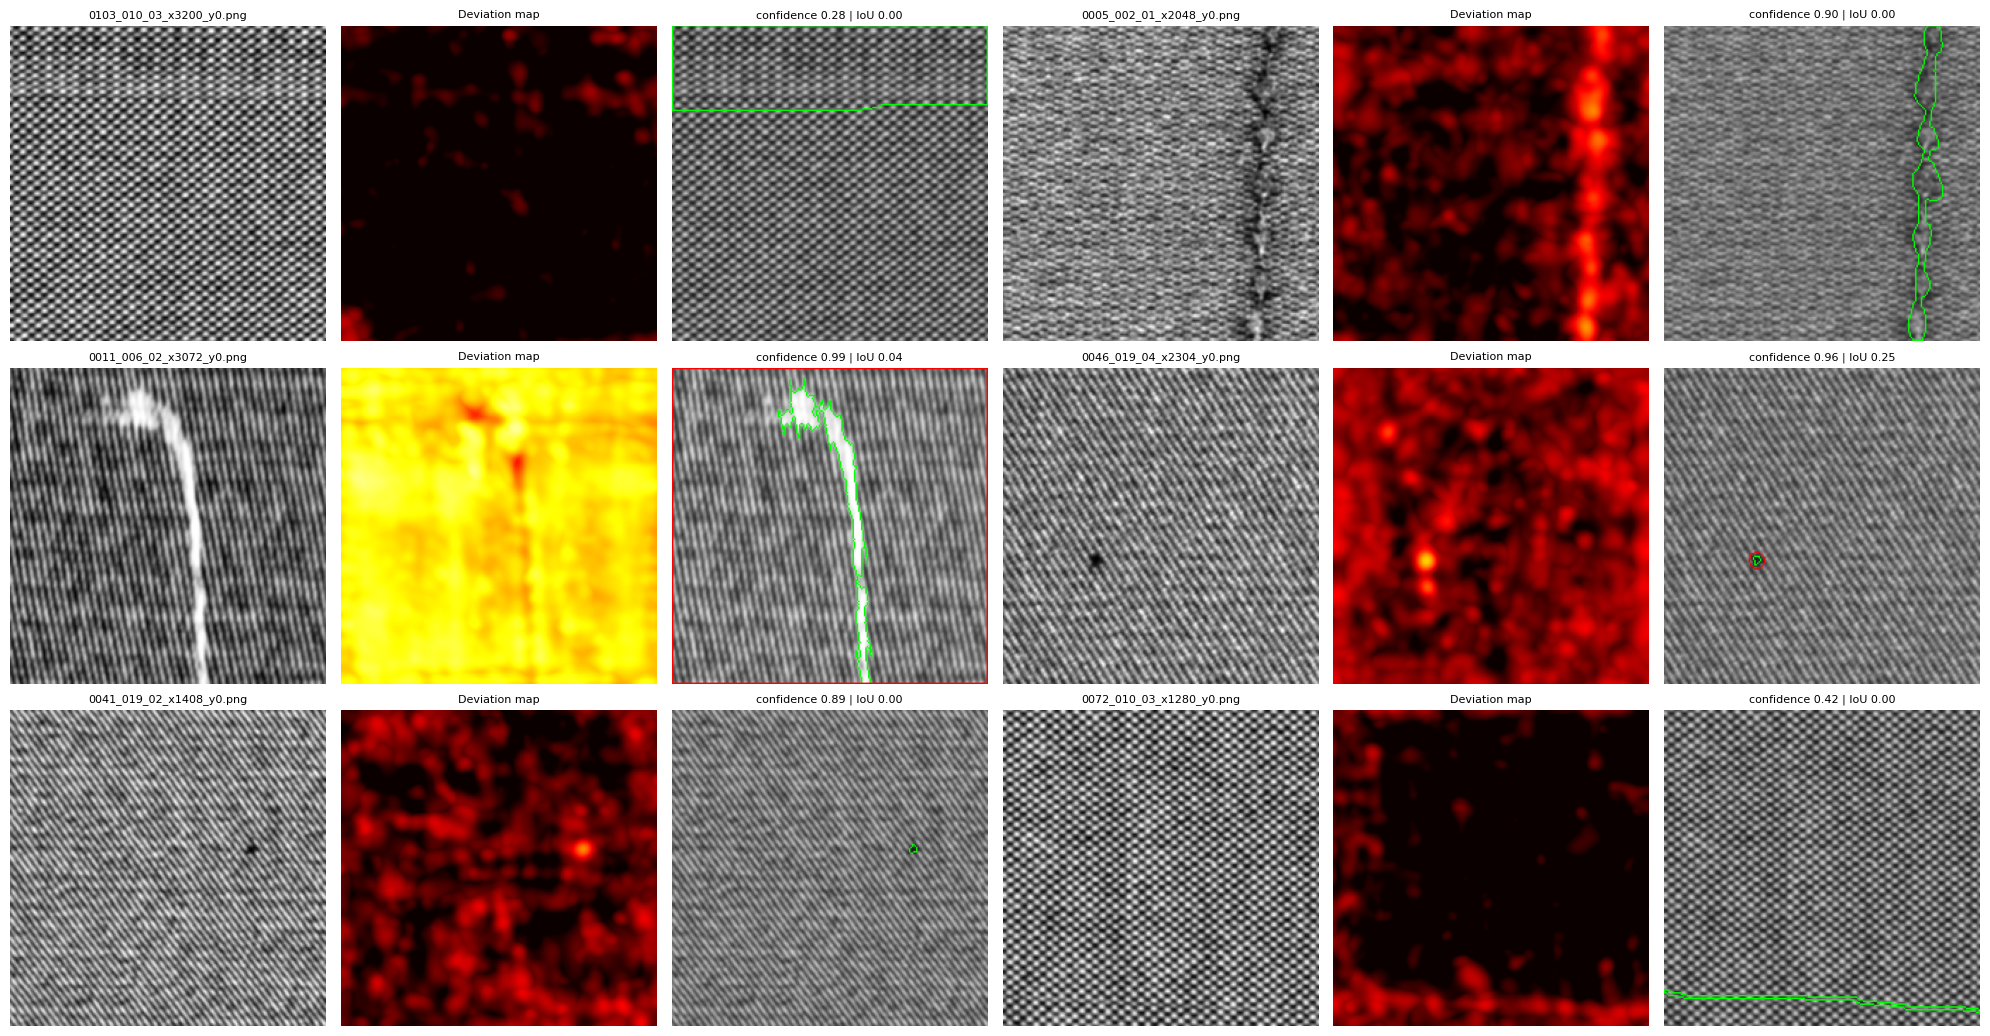

In [18]:
def overlay_contours(img, pred, gt):
    rgb = cv2.cvtColor(np.clip(img, 0, 255).astype(np.uint8), cv2.COLOR_GRAY2RGB)
    for m, col in ((gt, (0, 255, 0)), (pred, (255, 0, 0))):
        cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(rgb, cnts, -1, col, 1)
    return rgb

def distinct_sources(order, k, taken=()):
    seen, out = set(taken), []
    for i in order:
        s = final_dev[i]["it"]["source"]
        if s not in seen:
            seen.add(s); out.append(i)
        if len(out) == k:
            break
    return out

by_size = sorted(range(len(final_dev)), key=lambda i: -int(final_dev[i]["it"]["gt"].sum()))
big = distinct_sources(by_size, 3)
shuffled = list(rng.permutation(len(final_dev)))
extra = distinct_sources(shuffled, 3, taken={final_dev[i]["it"]["source"] for i in big})
pick = big + extra

fig, axes = plt.subplots(3, 6, figsize=(20, 10.5))
for k, i in enumerate(pick):
    f = final_dev[i]; it = f["it"]; model = get_model(BEST, it["fabric"])
    r, c = divmod(k, 2)
    base = interior(it["img"])
    axes[r, 3 * c].imshow(base, cmap="gray")
    axes[r, 3 * c].set_title(f"{it['name']}", fontsize=8)
    axes[r, 3 * c + 1].imshow(f["D"], cmap="hot", vmin=0, vmax=1.5 * model["thr"])
    axes[r, 3 * c + 1].set_title("Deviation map", fontsize=8)
    axes[r, 3 * c + 2].imshow(overlay_contours(base, f["res"]["mask"], it["gt"]))
    axes[r, 3 * c + 2].set_title(f"confidence {f['res']['conf']:.2f} | IoU {f['iou']:.2f}", fontsize=8)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

**OVERLAYS: FAILURE CASES**  
Top row: defects the pipeline missed or barely covered (largest first). Bottom row: defect-free patches it flagged with the highest confidence.

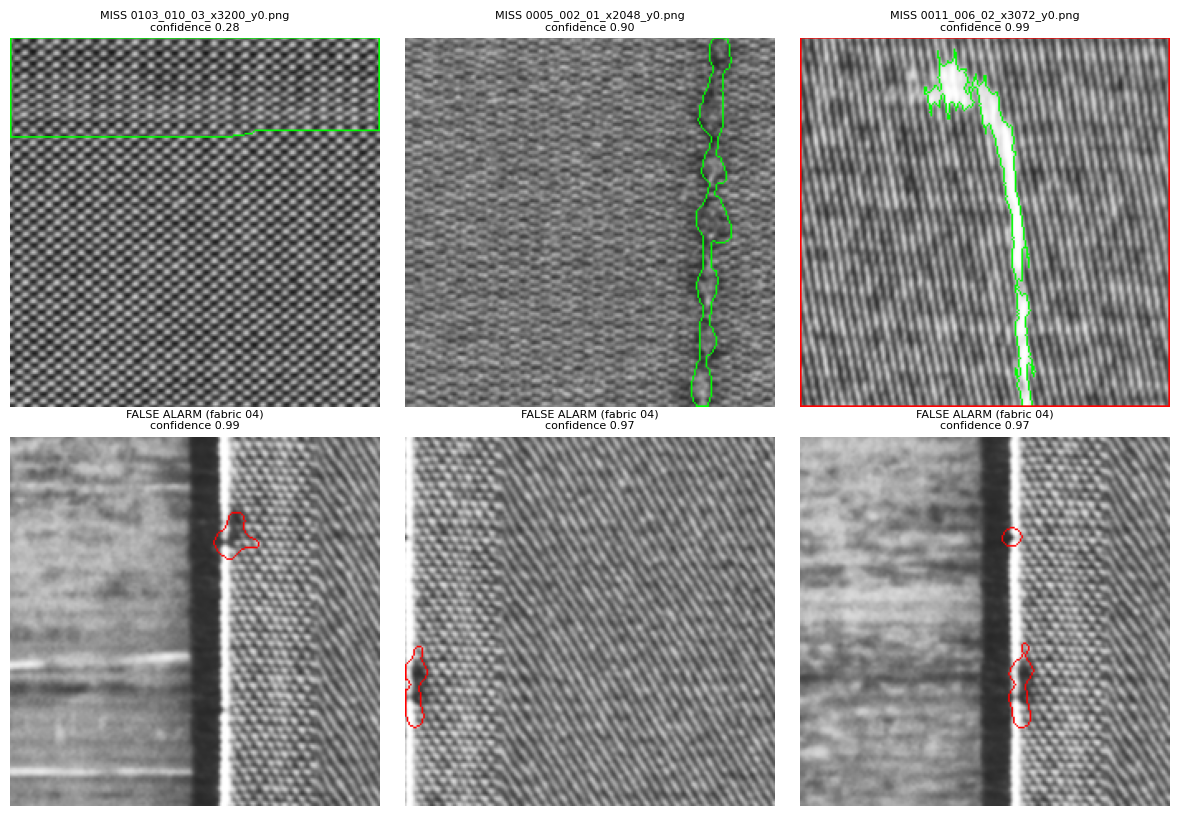

Misses shown: 3 | false alarms shown: 3


In [19]:
misses = [i for i in by_size if final_dev[i]["iou"] < 0.1]
miss_pick = distinct_sources(misses, 3)
fa_order = sorted([j for j in range(len(final_ntest)) if final_ntest[j]["res"]["flag"]],
                  key=lambda j: -final_ntest[j]["res"]["conf"])[:3]

fig, axes = plt.subplots(2, 3, figsize=(12, 8.2))
for ax in axes.ravel():
    ax.axis("off")
for k, i in enumerate(miss_pick):
    f = final_dev[i]; it = f["it"]
    axes[0, k].imshow(overlay_contours(interior(it["img"]), f["res"]["mask"], it["gt"]))
    axes[0, k].set_title(f"MISS {it['name']}\nconfidence {f['res']['conf']:.2f}", fontsize=8)
for k, j in enumerate(fa_order):
    f = final_ntest[j]
    axes[1, k].imshow(overlay_contours(interior(f["it"]["img"]), f["res"]["mask"], np.zeros_like(f["res"]["mask"])))
    axes[1, k].set_title(f"FALSE ALARM (fabric {f['it']['fabric']})\nconfidence {f['res']['conf']:.2f}", fontsize=8)
plt.tight_layout()
plt.show()
print(f"Misses shown: {len(miss_pick)} | false alarms shown: {len(fa_order)}")

**RAW IMAGE TO MASK AND CONFIDENCE**  
The full pipeline on whole raw strips: the same preprocessing as the patch dataset, 256x256 patches with stride 128, per-patch prediction with the fabric's model, and stitching of the patch interiors. Shown on DEV strips only (red = prediction, green = ground truth).

RAW STRIP PREDICTIONS (DEV strips)
0103_010_03 (fabric 03): detections 0, top confidence 0.00, strip IoU 0.000, precision 0.000, recall 0.000
0005_002_01 (fabric 01): detections 6, top confidence 0.98, strip IoU 0.000, precision 0.000, recall 0.000
0011_006_02 (fabric 02): detections 4, top confidence 1.00, strip IoU 0.003, precision 0.003, recall 1.000


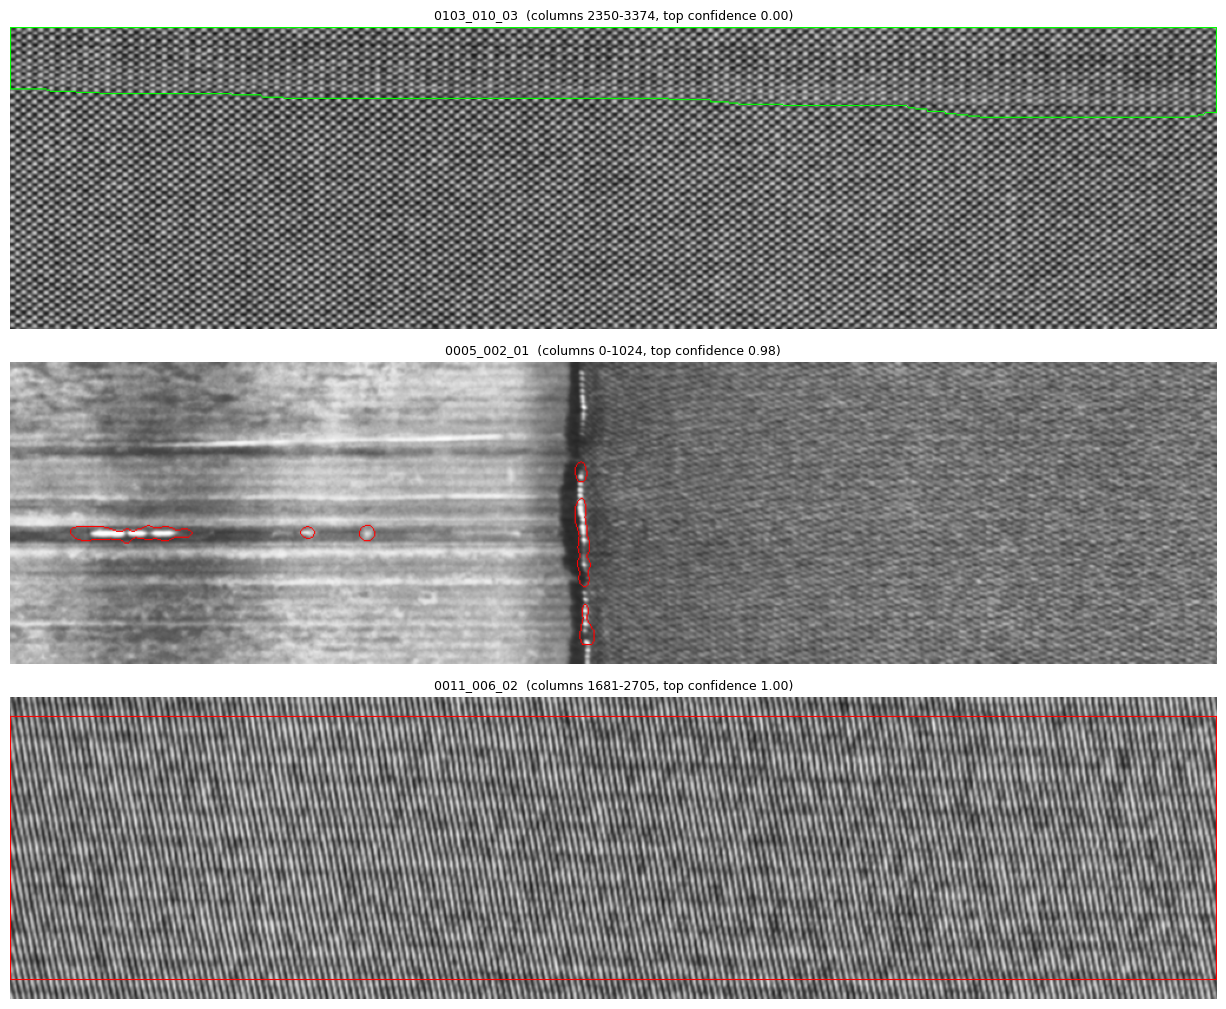


Note: the outer border margin of each patch is not scored, so a thin band along the strip edges is not covered.


In [20]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

def preprocess_image(image):
    if not CFG["clahe_preprocess"]:
        return cv2.GaussianBlur(image, (3, 3), 0)
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    enhanced = cv2.cvtColor(cv2.merge([clahe.apply(l_channel), a_channel, b_channel]), cv2.COLOR_LAB2BGR)
    return cv2.GaussianBlur(enhanced, (3, 3), 0)

PATCH, STEP = 256, 128

def predict_strip(path, pipeline):
    bgr = cv2.imread(str(path))
    gray = cv2.cvtColor(preprocess_image(bgr), cv2.COLOR_BGR2GRAY).astype(np.float32)
    H, Wd = gray.shape
    fabric = get_fabric_type(Path(path).stem)
    model = get_model(pipeline, fabric)
    m = CFG["border_margin"]
    xs = list(range(0, Wd - PATCH + 1, STEP))
    if xs[-1] != Wd - PATCH:
        xs.append(Wd - PATCH)
    mask = np.zeros((H, Wd), dtype=bool)
    score = np.full((H, Wd), -np.inf, dtype=np.float32)
    covered = np.zeros((H, Wd), dtype=bool)
    for x in xs:
        patch = gray[0:PATCH, x:x + PATCH]
        D = deviation_map(patch, model)
        res = predict_from_D(D, model)
        sl = (slice(m, PATCH - m), slice(x + m, x + PATCH - m))
        mask[sl] |= res["mask"]
        score[sl] = np.maximum(score[sl], D)
        covered[sl] = True
    mask = remove_small(mask, CFG["min_area"])
    blobs = describe_blobs(mask, np.where(covered, score, 0), model)
    return gray, mask, covered, blobs, fabric

def combine_gt(stem, shape):
    gt = np.zeros(shape, dtype=bool)
    for p in sorted(MASK_DIR.glob(f"{stem}_mask*.png")):
        m = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
        if m is not None:
            gt |= (m > 0)
    return gt

if not DEFECT_IMAGE_DIR.exists():
    print("Raw defect image folder not found; skipping the raw-image demo.")
else:
    dev_sources = (defect_df[defect_df.split == "dev"].groupby(["source", "fabric"]).defect_px.sum()
                   .reset_index().sort_values("defect_px", ascending=False))
    chosen, seen_fab = [], set()
    for _, r in dev_sources.iterrows():
        if (DEFECT_IMAGE_DIR / f"{r.source}.png").exists() and r.fabric not in seen_fab:
            chosen.append(r.source); seen_fab.add(r.fabric)
        if len(chosen) == 3:
            break
    fig, axes = plt.subplots(len(chosen), 1, figsize=(15, 3.4 * max(len(chosen), 1)))
    axes = np.atleast_1d(axes)
    print("=" * 60)
    print("RAW STRIP PREDICTIONS (DEV strips)")
    print("=" * 60)
    for ax, source in zip(axes, chosen):
        gray, mask, covered, blobs, fabric = predict_strip(DEFECT_IMAGE_DIR / f"{source}.png", BEST)
        gt = combine_gt(source, gray.shape)
        g, p = gt & covered, mask & covered
        tp = int((p & g).sum()); fp = int((p & ~g).sum()); fn = int((~p & g).sum())
        top_conf = max((b["conf"] for b in blobs), default=0.0)
        print(f"{source} (fabric {fabric}): detections {len(blobs)}, top confidence {top_conf:.2f}, "
              f"strip IoU {tp / (tp + fp + fn + 1e-9):.3f}, precision {tp / (tp + fp + 1e-9):.3f}, recall {tp / (tp + fn + 1e-9):.3f}")
        cols = np.nonzero((gt | mask).any(axis=0))[0]
        center = int(cols.mean()) if len(cols) else gray.shape[1] // 2
        x0 = int(np.clip(center - 512, 0, max(gray.shape[1] - 1024, 0))); x1 = min(x0 + 1024, gray.shape[1])
        ax.imshow(overlay_contours(gray[:, x0:x1], mask[:, x0:x1], gt[:, x0:x1]))
        ax.set_title(f"{source}  (columns {x0}-{x1}, top confidence {top_conf:.2f})", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    plt.show()
    print("\nNote: the outer border margin of each patch is not scored, so a thin band along the strip edges is not covered.")

**OPTIONAL: NOTCH SENSITIVITY**  
Turn on RUN_ABLATION to refit the adaptive pipeline under a few notch settings and compare Macro AP on DEV (takes several minutes). It checks whether keeping a fraction of the notched frequencies, or changing the peak rule, helps line-like defects.

In [21]:
RUN_ABLATION = False

if RUN_ABLATION:
    variants = {"default": {}, "peak_k=4": {"peak_k": 4.0}, "peak_k=10": {"peak_k": 10.0},
                "dilate_r=1": {"dilate_r": 1}, "dilate_r=3": {"dilate_r": 3}, "notch_depth=0.2": {"notch_depth": 0.2}}
    ab_rows = []
    for name, over in variants.items():
        cfg_v = {**CFG, **over}
        mods = build_adaptive_models(cfg_v)
        subs = []
        for it in dev_items:
            D = deviation_map(it["img"], mods[it["fabric"]])
            subs.append((it["fabric"], (D - mods[it["fabric"]]["thr"])[::2, ::2].ravel(), it["gt"][::2, ::2].ravel()))
        aps = []
        for fab in FABRICS:
            sel = [s for s in subs if s[0] == fab]
            if sel:
                gf = np.concatenate([s[2] for s in sel])
                if gf.any():
                    aps.append(average_precision_score(gf, np.concatenate([s[1] for s in sel])))
        ab_rows.append(dict(variant=name, MacroAP=float(np.mean(aps))))
    print("=" * 60)
    print("NOTCH SENSITIVITY (adaptive pipeline, DEV)")
    print("=" * 60)
    print(pd.DataFrame(ab_rows).round(3).to_string(index=False))
else:
    print("Skipped. Set RUN_ABLATION = True to run the notch sensitivity check.")

Skipped. Set RUN_ABLATION = True to run the notch sensitivity check.


**OPTIONAL: PATCHES WITHOUT CLAHE**  
Contrast equalisation can distort a periodic texture non-uniformly, which may hide defects from a spectral method. Set BUILD_NOCLAHE_PATCHES = True to write a second patch set (same positions and exclusions, Gaussian blur only) to a new folder; existing files are not touched. To compare, point PATCHED_DIR at the new folder in the load cell, set clahe_preprocess=False in CFG (so the raw-image demo matches), and rerun the notebook.

In [22]:
BUILD_NOCLAHE_PATCHES = False

def positions(n):
    xs = list(range(0, n - PATCH + 1, STEP))
    if not xs:
        return []
    if xs[-1] != n - PATCH:
        xs.append(n - PATCH)
    return xs

if BUILD_NOCLAHE_PATCHES:
    OUT = Path("/content/drive/MyDrive/ECE501/processed_patches_noclahe")
    for sub in ("images", "masks", "nodefect_images"):
        (OUT / sub).mkdir(parents=True, exist_ok=True)
    n_def = n_free = 0
    for p in sorted(DEFECT_IMAGE_DIR.glob("*.png")):
        bgr = cv2.imread(str(p))
        if bgr is None:
            continue
        gt = combine_gt(p.stem, bgr.shape[:2])
        if not gt.any():          # no mask or empty mask: excluded, as in the existing patch set
            continue
        img = cv2.GaussianBlur(bgr, (3, 3), 0)
        for y in positions(img.shape[0]):
            for x in positions(img.shape[1]):
                cv2.imwrite(str(OUT / "images" / f"{p.stem}_x{x}_y{y}.png"), img[y:y + PATCH, x:x + PATCH])
                cv2.imwrite(str(OUT / "masks" / f"{p.stem}_x{x}_y{y}.png"),
                            (gt[y:y + PATCH, x:x + PATCH] * 255).astype(np.uint8))
                n_def += 1
    for p in sorted(NODEFECT_IMAGE_DIR.rglob("*.png")):
        bgr = cv2.imread(str(p))
        if bgr is None:
            continue
        img = cv2.GaussianBlur(bgr, (3, 3), 0)
        for y in positions(img.shape[0]):
            for x in positions(img.shape[1]):
                cv2.imwrite(str(OUT / "nodefect_images" / f"{p.stem}_x{x}_y{y}.png"), img[y:y + PATCH, x:x + PATCH])
                n_free += 1
    print(f"Wrote {n_def} defect patches and {n_free} defect-free patches to {OUT}")
else:
    print("Skipped. Set BUILD_NOCLAHE_PATCHES = True to build the no-CLAHE patch set.")

Skipped. Set BUILD_NOCLAHE_PATCHES = True to build the no-CLAHE patch set.


**WEEK 6 SUMMARY**  
What was built, how it was evaluated, and what stays held out.

In [23]:
print("=" * 60)
print("WEEK 6 SUMMARY")
print("=" * 60)
print("Method              : FFT spectral residual (periodic notch + residual energy)")
print(f"Pipelines compared  : {', '.join(PIPELINES)}")
print(f"Carried forward     : {BEST} (highest Macro AP on DEV)")
print(f"Adaptive rule       : windows >= {CFG['c_periods']} periods, {CFG['n_adapt_scales']} scales, smoothing = {CFG['sigma_periods']} x period")
print(f"Threshold           : flags {CFG['target_fpr']:.0%} of normal patches ({CFG['thr_estimator']} fit), per model")
print(f"Mask clean-up       : growth fraction {LOW_FRAC} (tuned on DEV), opening r={CFG['r_open']}, closing r={CFG['r_close']}, blobs < {CFG['min_area']} px removed")
print("Confidence          : P(normal patch scores below the peak), calibrated on defect-free CAL patches")
print(f"Evaluated on        : DEV split only ({len(dev_items)} defect patches, interior, margin {CFG['border_margin']} px); TEST untouched")
print("\nDeviation-map quality (DEV):")
print(pd.DataFrame(quality).T.round(3).to_string())
print("\nMask strategies (DEV):")
print(strategy_df[["Pooled P", "Pooled R", "Pooled F1", "Over-seg ratio", "Defect-patch detection", "Normal-patch FPR"]].round(3).to_string())
print("\nNote: these numbers use a different protocol from earlier patch-level experiments")
print("(more patches, calibrated thresholds, per-fabric references, interior scoring), so they")
print("are not directly comparable. The final comparison re-runs every method under this protocol.")

WEEK 6 SUMMARY
Method              : FFT spectral residual (periodic notch + residual energy)
Pipelines compared  : Fixed single-scale, Fixed multi-scale, Adaptive multi-scale
Carried forward     : Fixed multi-scale (highest Macro AP on DEV)
Adaptive rule       : windows >= 4 periods, 3 scales, smoothing = 1.0 x period
Threshold           : flags 5% of normal patches (gumbel fit), per model
Mask clean-up       : growth fraction 0.7 (tuned on DEV), opening r=1, closing r=3, blobs < 16 px removed
Confidence          : P(normal patch scores below the peak), calibrated on defect-free CAL patches
Evaluated on        : DEV split only (152 defect patches, interior, margin 16 px); TEST untouched

Deviation-map quality (DEV):
                         AP  MacroAP  AUROC
Fixed single-scale    0.035    0.116  0.551
Fixed multi-scale     0.036    0.209  0.552
Adaptive multi-scale  0.080    0.084  0.797

Mask strategies (DEV):
                          Pooled P  Pooled R  Pooled F1  Over-seg ratio  